In [8]:
%pip install reservoirpy

#Referencia para la instalación:
#Nathan Trouvain, Luca Pedrelli, Thanh Trung Dinh, Xavier Hinaut. ReservoirPy: an Efficient and User-Friendly Library to Design Echo State Networks. 2020. ⟨hal-02595026⟩ https://hal.inria.fr/hal-02595026

In [9]:
import reservoirpy as rpy
from reservoirpy.nodes import Reservoir
#reservoirpy.hyper para automatizar la busqueda de los mejores parametros
rpy.set_seed(42)
#reservoir = Reservoir()

In [10]:
#PArte 1 : datos simulados
#usando lorenz 96 su ec.diferencial


#solucion por runge kuta 4
import numpy as np
import os

# parte 1: datos simulados con lorenz 96, resuelto con runge kutta 4
#esto para definir
def lorenz96(x, F):
    # dx_j/dt = (x_{j+1} - x_{j-2}) * x_{j-1} - x_j + F
    Q = len(x)
    dx = np.zeros(Q)
    for j in range(Q):
        # indices modulo Q -> frontera periodica
        dx[j] = (x[(j+1) % Q] - x[(j-2) % Q]) * x[(j-1) % Q] - x[j] + F
    return dx

def paso_rk4(x, F, dt):
    k1 = lorenz96(x, F)
    k2 = lorenz96(x + 0.5*dt*k1, F)
    k3 = lorenz96(x + 0.5*dt*k2, F)
    k4 = lorenz96(x + dt*k3, F)
    return x + (dt/6.0)*(k1 + 2*k2 + 2*k3 + k4)

def generar_datos(Q=36, F=8.0, dt=0.01, pasos_guardados=20000, cada=5, transitorio=5000):
  # condicion inicial: todo en F y una perturbacion  en x_0 pARA QUE SEA CAHOTIIC
    x = F*np.ones(Q)
    x[0] += 0.01

    # descartamos el transitorio (los datos del inicio pues que se ven muy afectados por las condiciones iniciales que deberian ser arbitrarias)
    for i in range(transitorio):
        x = paso_rk4(x, F, dt)

    # filas = tiempo, columnas = variables
    U = np.zeros((pasos_guardados, Q))
    fila = 0
    paso = 0
    while fila < pasos_guardados:
        x = paso_rk4(x, F, dt)
        if paso % cada == 0:      # guardamos 1 de cada 'cada' pasosss
            U[fila] = x
            fila += 1
        paso += 1

    return U

U = generar_datos()
print("Forma de los datos (tiempo, variables):", U.shape)
print("Primeras 2 filas:\n", U[:2])
#crear la super carpeta de los datoos
os.makedirs("datos", exist_ok=True)
np.save("datos/lorenz96.npy", U)
print("Guardado en datos/lorenz96.npy")

Forma de los datos (tiempo, variables): (20000, 36)
Primeras 2 filas:
 [[-0.72552264  2.46472299  2.60883472  5.45255529  1.74731621 -2.37615039
   0.64781479  8.70511315  0.28256157 -3.43517844  2.86822872  6.73450659
   2.5924355   4.30623275  4.48957027 -3.56568276  1.46102138  2.08373188
   8.02555054 -0.7573825  -1.05184529  1.23361959 11.73920185  0.9242563
  -3.12329854  1.65634572  5.60604995 -0.86357717 -2.52971346  0.93004597
   5.80407296  9.27354826 -0.74485182 -7.00972019  0.02183535  8.62157974]
 [ 1.40011479  2.68229973  3.53175745  5.35580666  0.6273682  -2.16005962
   0.16795516  8.71226538 -0.84413049 -2.77153233  1.98131926  7.52128444
   3.47426206  4.00056155  3.32244208 -3.46651724  1.98718824  3.35209442
   7.62759824 -1.61691273 -0.22402033  1.1561396  11.58827876 -1.03969725
  -2.52276129  1.14342417  5.84380594 -1.42154413 -1.726385    0.52277466
   6.29064089  8.01817897 -5.48787493 -4.59429499 -2.98773587  8.13087605]]
Guardado en datos/lorenz96.npy


In [29]:
#entrenamiento de la red neuronal
from reservoirpy.nodes import Reservoir, Ridge, Input, NVAR
from reservoirpy.observables import nrmse
import matplotlib.pyplot as plt


#cada fila es un instante de tiempo y las columnas son las variables, (20000,36)
U = np.load("datos/lorenz96.npy")   #ahh, los 36 salen de aquí, es pq el sistema lorenz tiene 36 variables

#Hay q elegir cierta cantidad de datos para entrenar la red
n_train = 15000
U_train = U[:n_train]
#otra para los test
U_test = U[n_train:]

media = U_train.mean(axis=0)
std = U_train.std(axis=0)

U_train_norm = (U_train - media) / std   #es para normalizar, pq como F=8, la función tanh se satura
U_test_norm = (U_test - media) / std    #también para normalizar

X_train = U_train_norm[:-1]
X_train = X_train + 0.015 * np.random.default_rng(42).standard_normal(X_train.shape)  #Hay que revisar, no funcionaba bien la predicción sin esta línea, esta agrega ruido
Y_train = U_train_norm[1:]


#Revisar por qué no funciona sin agregar ruido y determinar que tanto cambian los resultados cambiando hiperparámetros


#Parámetros
reservoir = Reservoir(units=1000,#cantidad de neuronas
    lr=1.0,                  #hay que mirar el dt y ajustarlo, pq si es muy grande la red no aprende, y si es muy pequeño tarda mucho en aprender
    sr=0.6,
    input_scaling=0.02,       #toca variar esto pq los datos meten 36 variables simultáneamente y eso puede saturar todo
    input_connectivity=0.1,
    rc_connectivity=0.05,    # Conectividad interna
    seed=42
)
readout = Ridge(ridge=1e-4)  #esto es para los pesos de salida y sirve para que la red no sobreajuste y pueda hacer la predicción


entrada = Input()
cuadraticos = NVAR(delay=1, order=2, strides=1) #términos cuadráticos
ESN = entrada >> reservoir >> readout & entrada >> cuadraticos >> readout   #Todo esto viene de q Lorenz no es lineal, había que corregir la red, se le tuvo que agregar estos términos cuadráticos

ESN.fit(X_train, Y_train, warmup=300)
ESN.reset()


step_warmup = 50
step_prediccion = 300
prediccion = ESN.run(U_test_norm[:step_warmup])  #iniciamos con 50 pasos para estabilizar la red y luego predecimos 300 pasos

predicciones_norm = np.zeros((step_prediccion, U.shape[1]))
u_actual = prediccion[-1:].ravel()  # última predicción del warmup, a partir de aquí empieza a predecir usando lo que ella misma retorna
predicciones_norm[0] = u_actual

for t in range(1, step_prediccion):
    u_actual = ESN(u_actual)  #usamos ahora la predicción
    predicciones_norm[t] = u_actual

Y_pred = predicciones_norm * std + media  #hay q desnormalizar para comparar con datos reales
Y_real = U_test[step_warmup : step_warmup + step_prediccion]


# ===== CRITERIO DE VALIDACION (tiempo de Lyapunov) =====
dt_datos    = 0.05                      # Δt entre filas guardadas (dt=0.01 * cada=5)
lambda_max  = 1.67                      # exponente de Lyapunov maximo (Lorenz-96, F=8, N=36)
t_lyapunov  = 1.0 / lambda_max          # ≈ 0.599 u.t.
pasos_por_lyap = t_lyapunov / dt_datos  # ≈ 12 pasos

# Error normalizado por paso (sobre datos normalizados)
Y_true_norm = U_test_norm[step_warmup : step_warmup + step_prediccion]
err_t = np.sqrt(((predicciones_norm - Y_true_norm)**2).mean(axis=1))

# Tiempo de prediccion valido: primer cruce del umbral
umbral = 0.3
cruce = np.argmax(err_t > umbral) if np.any(err_t > umbral) else step_prediccion
t_valido_ut   = cruce * dt_datos
t_valido_lyap = t_valido_ut / t_lyapunov

print(f"Prediccion valida: {cruce} pasos = {t_valido_ut:.2f} u.t. = {t_valido_lyap:.2f} tiempos de Lyapunov")



#La predicción no es válida a partir de cierto punto, ya q el sistema está regido por el Tiempo de Lyapunov
#Para nuestros datos generados, es de aproximadamente 0.59 unidades de tiempo o equivalentemente 1.67 en el máximo exponente de Lyapunov.
#Por lo que entendemos, la predicción es válida apenas para unos 30 pasos aproximadamente.

Prediccion valida: 32 pasos = 1.60 u.t. = 2.67 tiempos de Lyapunov


Error Normalizado: 0.2300


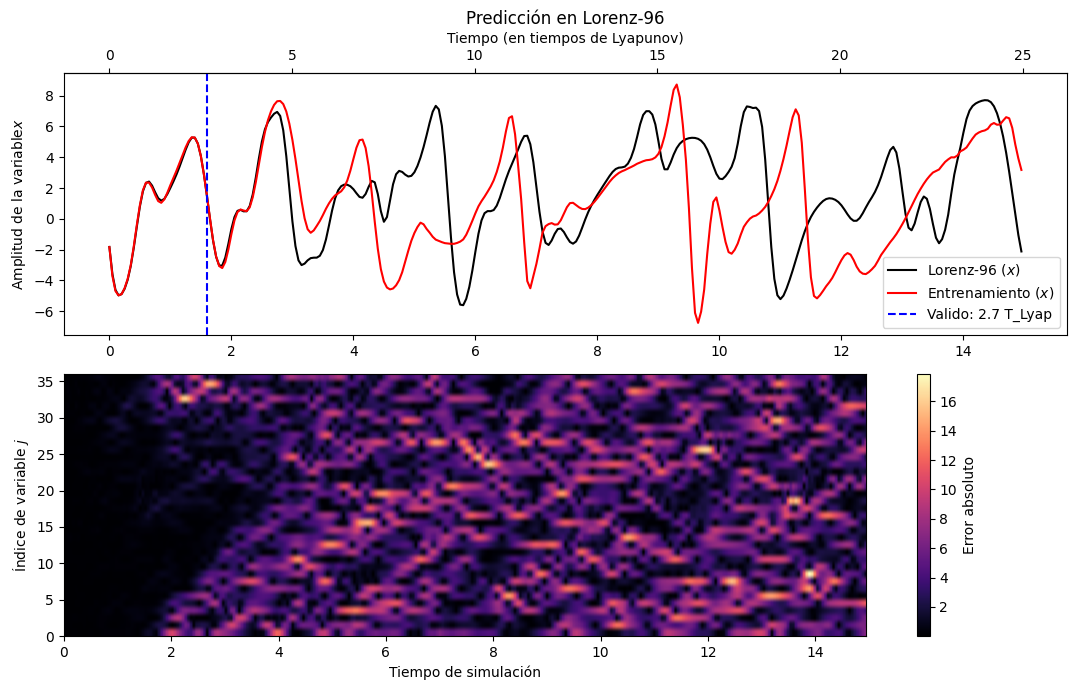

In [30]:
tiempo = np.arange(step_prediccion) * 0.05
fig, axes = plt.subplots(2, 1, figsize=(11, 7))

#Predicción para una variable, puede verse de 0 a 35
axes[0].plot(tiempo, Y_real[:, 11], label="Lorenz-96 ($x$)", color="black")
axes[0].plot(tiempo, Y_pred[:, 11], label="Entrenamiento ($x$)", color="red")
axes[0].set_ylabel("Amplitud de la variable$x$")
axes[0].set_title("Predicción en Lorenz-96")
axes[0].legend()

axes[0].axvline(t_valido_ut, color="blue", ls="--",
                label=f"Valido: {t_valido_lyap:.1f} T_Lyap")
axes[0].legend()   # vuelve a llamarlo para que aparezca la linea azul
secax = axes[0].secondary_xaxis('top',
    functions=(lambda t: t / t_lyapunov, lambda l: l * t_lyapunov))
secax.set_xlabel("Tiempo (en tiempos de Lyapunov)")


print(f"Error Normalizado: {nrmse(Y_real[:], Y_pred[:]):.4f}")
#Error para todas las variables en cada paso de tiempo
error_abs = np.abs(Y_real - Y_pred).T
im = axes[1].imshow(error_abs, aspect="auto", origin="lower",
                    extent=[tiempo[0], tiempo[-1], 0, U.shape[1]], cmap="magma")
axes[1].set_ylabel("Índice de variable $j$")
axes[1].set_xlabel("Tiempo de simulación")
fig.colorbar(im, ax=axes[1], label="Error absoluto")

plt.tight_layout()
plt.savefig("prediccion_lorenz96.png")
plt.show()